# Dataset Distribution & Calorimeter Ring Energy Profiles

This notebook provides a memory-efficient streaming pipeline to analyze egamma calorimeter data across $E_T \times \eta$ regions:
1. **Per-Region Streaming & Column Masking**: Reads one region at a time with all 182 columns preserved, masks the required columns for each method (linear cuts / observables, 100-ring energy profiles, and 50-ring energy profiles), plots and frees RAM immediately.
2. **Unfilled Step Histograms**: Step outline histograms (`histtype='step'`) for clean, transparent multi-class visual comparison.
3. **Calorimeter Ring Energy Profiles**: Average energy profiles for **100 rings** (`percentage=1.0`) and **50 rings** (`percentage=0.5`) models using `ProfileMeanEnergyPlotter` with unified 0-indexed ring axis values and subdetector demarcations.
4. **Execution Control**: A flag (`READ_ALL_DATASETS`) allowing quick test runs on the first region or full processing over all regions.
5. **Global All-Regions Machine Behavior (Last Cell)**: Consolidates accumulated observable distributions and regional event yields across the entire calorimeter phase space.

In [1]:
import gc
import os
import sys
from pathlib import Path
from types import SimpleNamespace

# Resolve project root directory
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mplhep as mh

mh.style.use("ATLAS")

from src.core.Datasets.EgammaNpzDataset import EgammaNpzDataset
from src.core.Plotting.ProfilePlotter import ProfileMeanEnergyPlotter
from src.core.Plotting.Context import RegionPlotContext
from src.utils import get_et_eta, norm1

print(f"Project root: {PROJECT_ROOT}")

Project root: /home/pmourafr/egamma_master


### 1. Configuration & Path Mapping
Configure dataset paths from the model YAML configurations, define the interchangeable target observable, and set execution flags.

In [2]:
# Model configuration files mapping dataset paths
CONFIG_PATH_100 = PROJECT_ROOT / "config/NeuralRinger/ModelV10_HighBatch_100Rings.yaml"
CONFIG_PATH_50 = PROJECT_ROOT / "config/NeuralRinger/ModelV10_HighBatch_50Rings.yaml"

with open(CONFIG_PATH_100, "r") as f:
    config_dict_100 = yaml.safe_load(f)

# Resolve dataset drive path (with fallback to local data/consolidated if path does not exist)
DATA_PATH = config_dict_100["dataset"]["parameters"]["drive_path"]
if not os.path.exists(DATA_PATH):
    local_data_path = PROJECT_ROOT / "data/consolidated"
    if local_data_path.exists():
        DATA_PATH = str(local_data_path)

print(f"Dataset path: {DATA_PATH}")

# Execution Flag: Set False for first region only (fast tests), True to process all regions
READ_ALL_DATASETS = False

# Interchangeable variable for distribution histogram (e.g. 'avgmu', 'ph_et', 'ph_eta', 'ph_Reta', 'trig_L2_calo_weta2')
TARGET_VARIABLE = "avgmu"

# Histogram styling parameters (unfilled step outline)
HIST_BINS = 50
NORMED_DENSITY = True
HIST_TYPE = "step"
HIST_LINEWIDTH = 2.0

# Output directory for saved plots
OUTPUT_DIR = PROJECT_ROOT / "Plots/dataset_distributions"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

Dataset path: /home/pmourafr/egamma_master/data/consolidated


### 2. Dataset Instantiation & Feature Inspection
Instantiate `dataset_100` and `dataset_50` to scan available region archives and establish ring index column mappings.

In [3]:
dataset_100 = EgammaNpzDataset(
    drive_path=DATA_PATH,
    startswith=config_dict_100["dataset"]["parameters"].get("startswith", "consolidated.et"),
    endswith=config_dict_100["dataset"]["parameters"].get("endswith", ".npz"),
    percentage=1.0,
)

dataset_50 = EgammaNpzDataset(
    drive_path=DATA_PATH,
    startswith=config_dict_100["dataset"]["parameters"].get("startswith", "consolidated.et"),
    endswith=config_dict_100["dataset"]["parameters"].get("endswith", ".npz"),
    percentage=0.5,
)

# Initialize ring column indices for both dataset configurations
feature_names = dataset_100.feature_names
dataset_50._set_ring_column_indices(feature_names)

print(f"Discovered region files: {len(dataset_100)}")
print(f"Active rings in 100-ring model: {dataset_100.percentage_dim}")
print(f"Active rings in 50-ring model:  {dataset_50.percentage_dim}")
print(f"Total columns available per event: {len(feature_names)}")

Discovered region files: 1
Active rings in 100-ring model: 100
Active rings in 50-ring model:  50
Total columns available per event: 182


### 3. Per-Region Streaming, Column Masking & Immediate Plotting
To avoid running out of memory, each region is read individually with all columns intact. We mask the required columns for:
- **Target Observable / Linear Cuts**: 1D distribution histogram (unfilled step outline).
- **100 Rings Model**: Calorimeter ring energy profile with unified axis values.
- **50 Rings Model**: Calorimeter ring energy profile with unified axis values.
Plots are generated and saved as PDF and PNG immediately, only 1D arrays are accumulated for the final machine behavior cell, and memory is freed with `del` and `gc.collect()`.

Target variable 'avgmu' resolved at column index: 0
Processing 1 region file(s) (READ_ALL_DATASETS=False)

Region et2_eta2 (ET=2, ETA=2) loaded from consolidated.et2.eta2.npz
  Signal events (Photons):       40991
  Background events (Had. Jets): 42950


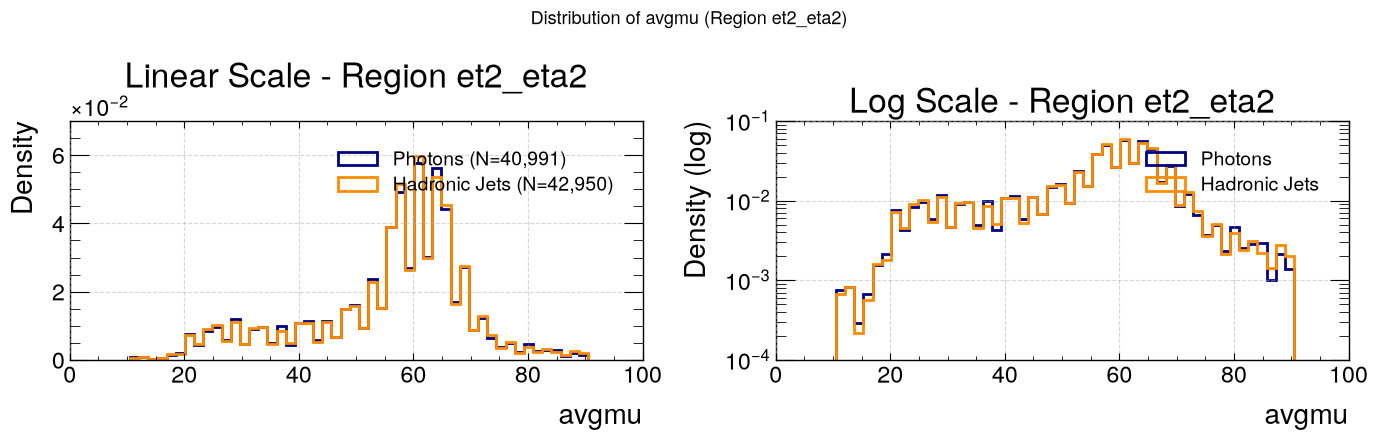

  [100 Rings] Official PDF saved: /home/pmourafr/egamma_master/Plots/dataset_distributions/RingsMeanProfiles/et2.eta2.RingsMeanProfiles_100Rings.pdf
  [50 Rings]  Official PDF saved: /home/pmourafr/egamma_master/Plots/dataset_distributions/RingsMeanProfiles/et2.eta2.RingsMeanProfiles_50Rings.pdf
  Region et2_eta2 completed. Memory freed successfully.



In [4]:
if TARGET_VARIABLE not in feature_names:
    raise ValueError(f"Variable '{TARGET_VARIABLE}' not found in dataset! Available: {list(feature_names)}")

target_var_idx = int(np.where(feature_names == TARGET_VARIABLE)[0][0])
print(f"Target variable '{TARGET_VARIABLE}' resolved at column index: {target_var_idx}")

total_files = len(dataset_100)
files_to_process = list(range(total_files)) if READ_ALL_DATASETS else [0]
print(f"Processing {len(files_to_process)} region file(s) (READ_ALL_DATASETS={READ_ALL_DATASETS})\n")

# Dedicated subfolder named after the target variable
var_output_dir = OUTPUT_DIR / TARGET_VARIABLE
var_output_dir.mkdir(parents=True, exist_ok=True)
print(f"Variable distribution plots will be saved to: {var_output_dir}")

profile_plotter = ProfileMeanEnergyPlotter()
subdet_names = ["PreSampler", "EM1", "EM2", "EM3", "TileCal"]
subdet_colors = ["#1b9e77", "#d95f09", "#7570b3", "#e7298a", "#66a61e"]

# Lightweight global collectors for the last cell (stores ONLY 1D arrays, no heavy matrices)
global_signal_values = []
global_bg_values = []
region_summaries = []

for idx in files_to_process:
    # 1. Load full 182-column data matrix for this region only
    data, labels, file_path = dataset_100[idx]
    et, eta = get_et_eta(file_path)
    region_key = f"et{int(et)}_eta{int(eta)}"
    
    signal_mask = (labels == 1)
    bg_mask = (labels == 0)
    n_sig = int(np.sum(signal_mask))
    n_bg = int(np.sum(bg_mask))
    
    print(f"{'='*70}")
    print(f"Region {region_key} (ET={et}, ETA={eta}) loaded from {os.path.basename(file_path)}")
    print(f"  Signal events (Photons):       {n_sig}")
    print(f"  Background events (Had. Jets): {n_bg}")
    
    # 2. Method A: Mask target variable / linear cut column for distribution plot
    var_signal = data[signal_mask, target_var_idx]
    var_bg = data[bg_mask, target_var_idx]
    
    # Accumulate 1D values for the last cell
    global_signal_values.append(var_signal)
    global_bg_values.append(var_bg)
    region_summaries.append({
        "region": region_key,
        "et": int(et),
        "eta": int(eta),
        "n_signal": n_sig,
        "n_bg": n_bg,
        "total": n_sig + n_bg,
    })
    
    # Plot 1D distribution with unfilled step bars
    q_low = min(float(np.percentile(var_signal, 0.1)), float(np.percentile(var_bg, 0.1)))
    q_high = max(float(np.percentile(var_signal, 99.9)), float(np.percentile(var_bg, 99.9)))
    val_range = (q_low, q_high)
    
    fig_dist, (ax_lin, ax_log) = plt.subplots(1, 2, figsize=(14, 4.5))
    ax_lin.hist(var_signal, bins=HIST_BINS, range=val_range, density=NORMED_DENSITY, histtype=HIST_TYPE, linewidth=HIST_LINEWIDTH, color="navy", label=f"Photons (N={n_sig:,})")
    ax_lin.hist(var_bg, bins=HIST_BINS, range=val_range, density=NORMED_DENSITY, histtype=HIST_TYPE, linewidth=HIST_LINEWIDTH, color="darkorange", label=f"Hadronic Jets (N={n_bg:,})")
    ax_lin.set_xlabel(TARGET_VARIABLE)
    ax_lin.set_ylabel("Density" if NORMED_DENSITY else "Counts")
    ax_lin.set_title(f"Linear Scale - Region {region_key}")
    ax_lin.legend(loc="upper right")
    ax_lin.grid(True, linestyle="--", alpha=0.5)
    
    ax_log.hist(var_signal, bins=HIST_BINS, range=val_range, density=NORMED_DENSITY, histtype=HIST_TYPE, linewidth=HIST_LINEWIDTH, color="navy", label="Photons")
    ax_log.hist(var_bg, bins=HIST_BINS, range=val_range, density=NORMED_DENSITY, histtype=HIST_TYPE, linewidth=HIST_LINEWIDTH, color="darkorange", label="Hadronic Jets")
    ax_log.set_yscale("log")
    ax_log.set_xlabel(TARGET_VARIABLE)
    ax_log.set_ylabel("Density (log)" if NORMED_DENSITY else "Counts (log)")
    ax_log.set_title(f"Log Scale - Region {region_key}")
    ax_log.legend(loc="upper right")
    ax_log.grid(True, linestyle="--", alpha=0.5)
    
    fig_dist.suptitle(f"Distribution of {TARGET_VARIABLE} (Region {region_key})", fontsize=13)
    plt.tight_layout()
    dist_file_png = var_output_dir / f"{region_key}_{TARGET_VARIABLE}_distribution.png"
    dist_file_pdf = var_output_dir / f"{region_key}_{TARGET_VARIABLE}_distribution.pdf"
    plt.savefig(dist_file_png, dpi=300, bbox_inches="tight")
    plt.savefig(dist_file_pdf, bbox_inches="tight")
    print(f"  Distribution plot saved to: {dist_file_pdf}")
    plt.show()
    
    # 3. Method B: Mask 100 ring columns and run ProfileMeanEnergyPlotter (saves official PDF)
    rings_100_cols = dataset_100.ring_column_indices
    mock_trainer_100 = SimpleNamespace(full_dataset=dataset_100)
    context_100 = RegionPlotContext(iet=int(et), ieta=int(eta), output_dir=OUTPUT_DIR, data=data, target=labels, trainer=mock_trainer_100)
    pdf_100 = profile_plotter.plot(context_100, x_rings=data[:, rings_100_cols], plot_name="RingsMeanProfiles_100Rings", plot_title=f"Average Energy Profile (100 Rings) - Region {region_key}")
    print(f"  [100 Rings] Official PDF saved: {pdf_100}")
    
    # 4. Method C: Mask 50 ring columns and run ProfileMeanEnergyPlotter (saves official PDF)
    rings_50_cols = dataset_50.ring_column_indices
    mock_trainer_50 = SimpleNamespace(full_dataset=dataset_50)
    context_50 = RegionPlotContext(iet=int(et), ieta=int(eta), output_dir=OUTPUT_DIR, data=data, target=labels, trainer=mock_trainer_50)
    pdf_50 = profile_plotter.plot(context_50, x_rings=data[:, rings_50_cols], plot_name="RingsMeanProfiles_50Rings", plot_title=f"Average Energy Profile (50 Rings) - Region {region_key}")
    print(f"  [50 Rings]  Official PDF saved: {pdf_50}")

    print(f"  Region {region_key} completed. Memory freed successfully.\n")

### 4. All-Regions Machine Behavior Study
Consolidated global analysis of the target observable across all accumulated regions, showing the machine's overall phase space distribution and event yield statistics across $E_T \times \eta$.

ALL REGIONS CONSOLIDATED MACHINE BEHAVIOR SUMMARY
Total Regions Processed:        1
Total Events in Dataset:        83,941
Total Signal Events (Photons):  40,991 (48.83%)
Total Background Events (Jets): 42,950 (51.17%)
avgmu Global Range:        [9.500, 90.500]

Saved global distribution plot to: /home/pmourafr/egamma_master/Plots/dataset_distributions/global_avgmu_distribution_all_regions.png


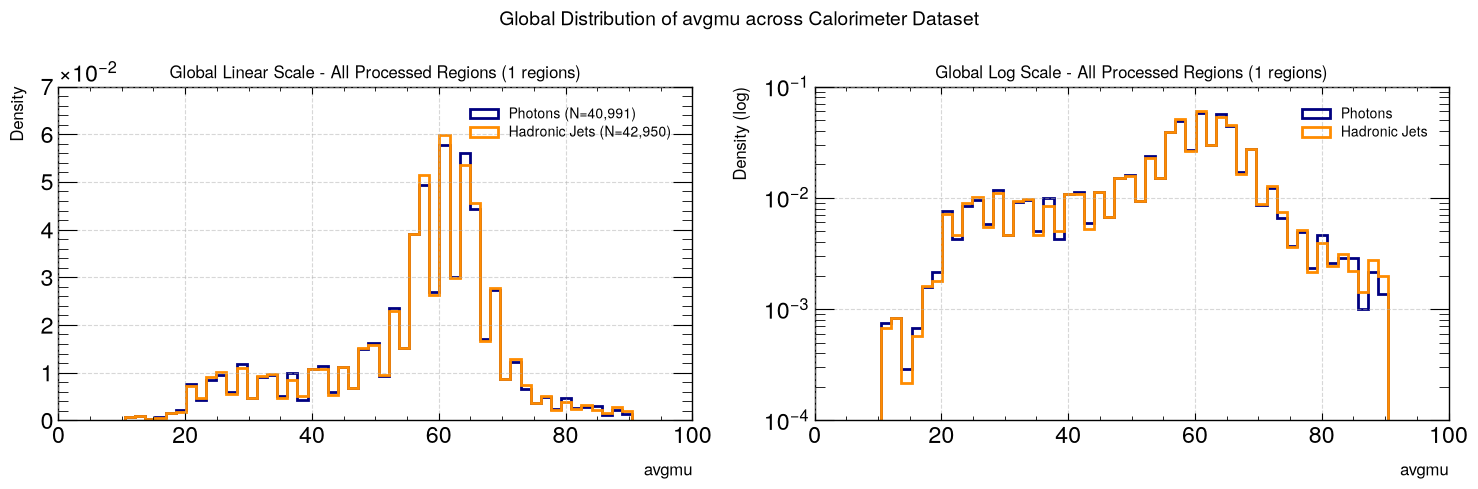

,region,et,eta,n_signal,n_bg,total
0,et2_eta2,2,2,40991,42950,83941


In [ ]:
# all_signal = np.concatenate(global_signal_values)
# all_bg = np.concatenate(global_bg_values)
# total_sig_events = len(all_signal)
# total_bg_events = len(all_bg)
# total_events = total_sig_events + total_bg_events

# print(f"{'='*70}")
# print("ALL REGIONS CONSOLIDATED MACHINE BEHAVIOR SUMMARY")
# print(f"{'='*70}")
# print(f"Total Regions Processed:        {len(region_summaries)}")
# print(f"Total Events in Dataset:        {total_events:,}")
# print(f"Total Signal Events (Photons):  {total_sig_events:,} ({total_sig_events / total_events * 100:.2f}%)")
# print(f"Total Background Events (Jets): {total_bg_events:,} ({total_bg_events / total_events * 100:.2f}%)")
# print(f"{TARGET_VARIABLE} Global Range:        [{all_signal.min():.3f}, {all_signal.max():.3f}]\n")

# # 1. Global Distribution Plot across all processed regions (unfilled step bars)
# g_low = min(float(np.percentile(all_signal, 0.1)), float(np.percentile(all_bg, 0.1)))
# g_high = max(float(np.percentile(all_signal, 99.9)), float(np.percentile(all_bg, 99.9)))
# g_range = (g_low, g_high)

# fig_global, (ax_glin, ax_glog) = plt.subplots(1, 2, figsize=(15, 5))

# # Global Linear Scale
# ax_glin.hist(all_signal, bins=HIST_BINS, range=g_range, density=NORMED_DENSITY, histtype=HIST_TYPE, linewidth=HIST_LINEWIDTH, color="navy", label=f"Photons (N={total_sig_events:,})")
# ax_glin.hist(all_bg, bins=HIST_BINS, range=g_range, density=NORMED_DENSITY, histtype=HIST_TYPE, linewidth=HIST_LINEWIDTH, color="darkorange", label=f"Hadronic Jets (N={total_bg_events:,})")
# ax_glin.set_xlabel(TARGET_VARIABLE, fontsize=12)
# ax_glin.set_ylabel("Density" if NORMED_DENSITY else "Counts", fontsize=12)
# ax_glin.set_title(f"Global Linear Scale - All Processed Regions ({len(region_summaries)} regions)", fontsize=12)
# ax_glin.legend(loc="upper right", fontsize=10)
# ax_glin.grid(True, linestyle="--", alpha=0.5)

# # Global Logarithmic Scale
# ax_glog.hist(all_signal, bins=HIST_BINS, range=g_range, density=NORMED_DENSITY, histtype=HIST_TYPE, linewidth=HIST_LINEWIDTH, color="navy", label=f"Photons")
# ax_glog.hist(all_bg, bins=HIST_BINS, range=g_range, density=NORMED_DENSITY, histtype=HIST_TYPE, linewidth=HIST_LINEWIDTH, color="darkorange", label=f"Hadronic Jets")
# ax_glog.set_yscale("log")
# ax_glog.set_xlabel(TARGET_VARIABLE, fontsize=12)
# ax_glog.set_ylabel("Density (log)" if NORMED_DENSITY else "Counts (log)", fontsize=12)
# ax_glog.set_title(f"Global Log Scale - All Processed Regions ({len(region_summaries)} regions)", fontsize=12)
# ax_glog.legend(loc="upper right", fontsize=10)
# ax_glog.grid(True, linestyle="--", alpha=0.5)

# fig_global.suptitle(f"Global Distribution of {TARGET_VARIABLE} across Calorimeter Dataset", fontsize=14)
# plt.tight_layout()
global_plot_png = var_output_dir / f"global_{TARGET_VARIABLE}_distribution_all_regions.png"
global_plot_pdf = var_output_dir / f"global_{TARGET_VARIABLE}_distribution_all_regions.pdf"
plt.savefig(global_plot_png, dpi=300, bbox_inches="tight")
plt.savefig(global_plot_pdf, bbox_inches="tight")
print(f"Saved global distribution plot to: {global_plot_pdf}")
# plt.show()

# # 2. Regional event count breakdown table
# df_summary = pd.DataFrame(region_summaries)
# if len(df_summary) > 1:
#     fig_bar, ax_bar = plt.subplots(figsize=(14, 5))
#     x_indices = np.arange(len(df_summary))
#     width = 0.35
#     ax_bar.bar(x_indices - width/2, df_summary["n_signal"], width, label="Photons", color="navy", alpha=0.8)
#     ax_bar.bar(x_indices + width/2, df_summary["n_bg"], width, label="Hadronic Jets", color="darkorange", alpha=0.8)
#     ax_bar.set_xticks(x_indices)
#     ax_bar.set_xticklabels(df_summary["region"], rotation=45, ha="right", fontsize=10)
#     ax_bar.set_xlabel("Calorimeter Kinematic Region (ET, ETA)", fontsize=11)
#     ax_bar.set_ylabel("Event Count", fontsize=11)
#     ax_bar.set_title("Event Yield Distribution across Calorimeter Regions", fontsize=13)
#     ax_bar.legend()
#     ax_bar.grid(True, linestyle="--", alpha=0.5)
#     plt.tight_layout()
#     regional_summary_path = OUTPUT_DIR / "regional_event_yields_summary.png"
#     plt.savefig(regional_summary_path, dpi=300, bbox_inches="tight")
#     print(f"Saved regional summary bar chart to: {regional_summary_path}")
#     plt.show()
    
# df_summary